# Predicción del consumo eléctrico mensual de viviendas

**Módulo:** Sistemas de Aprendizaje Automático · **Tipo de problema:** regresión supervisada
**Variable objetivo:** `consumo_mensual_kwh`

El trabajo se divide en dos etapas para poder comparar resultados:

1. **Etapa 1:** variables elegidas *a priori*, según lo que intuitivamente debería influir en el consumo.
2. **Etapa 2:** variables elegidas *a partir de un análisis exploratorio* hecho solo con los datos de entrenamiento.

En las dos etapas se usan los mismos 4 algoritmos y la **misma partición 70 % / 30 %**, así que las diferencias
de MAE se deben solo a la selección de variables.

**Índice**
1. Librerías y configuración
2. Carga de datos
3. Cribado de datos
4. Partición entrenamiento / test (70/30)
5. Funciones auxiliares (preparación, modelos y evaluación)
6. Etapa 1: variables elegidas a priori
7. Etapa 2: variables elegidas mediante análisis exploratorio
8. Comparación final de ambas etapas

## 1. Librerías y configuración

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42          # semilla común para que todo sea reproducible
OBJETIVO = "consumo_mensual_kwh"

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 100

## 2. Carga de datos
Se carga el CSV y se revisa su estructura: número de filas y columnas, tipos de datos y primeras filas.

In [2]:
datos = pd.read_csv("dataset_consumo_electrico_30000.csv")
print("Dimensiones:", datos.shape)
datos.info()
datos.head()

Dimensiones: (30000, 24)
<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 24 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id_registro               30000 non-null  int64  
 1   edad_vivienda_anios       30000 non-null  int64  
 2   superficie_m2             29997 non-null  float64
 3   numero_personas           29988 non-null  float64
 4   habitaciones              29987 non-null  float64
 5   dias_facturacion          29980 non-null  float64
 6   temperatura_media_c       29991 non-null  float64
 7   temperatura_minima_c      29989 non-null  float64
 8   temperatura_maxima_c      29999 non-null  float64
 9   mes                       30000 non-null  int64  
 10  zona_climatica            30000 non-null  str    
 11  tipo_vivienda             30000 non-null  str    
 12  nivel_aislamiento         30000 non-null  str    
 13  tipo_calefaccion          30000 non-null  str  

,id_registro,edad_vivienda_anios,superficie_m2,numero_personas,habitaciones,dias_facturacion,temperatura_media_c,temperatura_minima_c,temperatura_maxima_c,mes,zona_climatica,tipo_vivienda,nivel_aislamiento,tipo_calefaccion,tipo_agua_caliente,aire_acondicionado,paneles_solares,numero_electrodomesticos,teletrabajo,nivel_ocupacion_diurna,potencia_contratada_kw,tipo_tarifa,anio,consumo_mensual_kwh
0,1,86,175.2,2.0,5.0,31.0,10.3,5.3,21.9,3,Mediterránea,Piso,Alto,Bomba de calor,Gas,No,No,7.0,No,Media,3.41,Fija,2026,601.7
1,2,18,146.6,3.0,5.0,31.0,8.2,-1.9,12.0,7,Continental,Piso,Medio,Bomba de calor,Gas,No,No,10.0,No,Alta,5.23,Fija,2021,731.6
2,3,2,103.8,4.0,2.0,30.0,19.8,7.2,25.0,12,Atlántica,Piso,Alto,Biomasa,Solar,Sí,No,8.0,Sí,Alta,4.54,Fija,2023,499.2
3,4,64,85.0,5.0,3.0,31.0,19.9,12.3,29.3,1,Continental,Casa,Alto,Gas,Gas,Sí,No,9.0,No,Alta,4.87,Fija,2023,721.2
4,5,36,74.8,2.0,1.0,30.0,9.7,1.8,13.8,5,Mediterránea,Piso,Bajo,Gas,Solar,No,No,4.0,No,Media,2.74,Fija,2023,314.8


## 3. Cribado de datos
Antes de entrenar se comprueba la calidad del dataset:

1. **Valores nulos** por columna.
2. **Registros duplicados**, con y sin `id_registro`.
3. **Rangos** de las variables numéricas, para detectar valores imposibles (superficies negativas, etc.).
4. **Coherencia de temperaturas:** mínima ≤ media ≤ máxima.
5. **Categorías**, para detectar erratas o etiquetas inconsistentes.

In [3]:
# 3.1 Valores nulos
nulos = datos.isna().sum()
print("Valores nulos por columna:")
print(nulos[nulos > 0])
print("Filas con al menos un nulo:", datos.isna().any(axis=1).sum(),
      f"({datos.isna().any(axis=1).mean():.2%} del total)")

Valores nulos por columna:
superficie_m2                3
numero_personas             12
habitaciones                13
dias_facturacion            20
temperatura_media_c          9
temperatura_minima_c        11
temperatura_maxima_c         1
paneles_solares              2
numero_electrodomesticos     4
nivel_ocupacion_diurna       1
potencia_contratada_kw       2
dtype: int64
Filas con al menos un nulo: 61 (0.20% del total)


In [4]:
# 3.2 Duplicados
print("Filas duplicadas:", datos.duplicated().sum())
print("Filas duplicadas sin contar id_registro:",
      datos.drop(columns="id_registro").duplicated().sum())

Filas duplicadas: 0
Filas duplicadas sin contar id_registro: 0


In [5]:
# 3.3 Rangos de las variables numéricas
datos.drop(columns="id_registro").describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
edad_vivienda_anios,30000.0,50.16,29.18,0.0,25.00,50.00,75.00,100.00
superficie_m2,29997.0,115.37,40.99,30.0,87.30,114.70,143.10,283.60
numero_personas,29988.0,3.57,1.59,1.0,2.00,3.00,5.00,8.00
habitaciones,29987.0,3.87,1.57,1.0,3.00,4.00,5.00,9.00
dias_facturacion,29980.0,30.43,0.67,28.0,30.00,30.00,31.00,31.00
temperatura_media_c,29991.0,16.01,7.91,-5.0,10.60,16.00,21.30,38.00
temperatura_minima_c,29989.0,7.52,8.30,-15.0,1.90,7.40,13.10,30.00
temperatura_maxima_c,29999.0,23.51,8.34,-1.8,17.80,23.50,29.20,48.00
mes,30000.0,6.49,3.44,1.0,3.00,7.00,9.00,12.00
numero_electrodomesticos,29996.0,7.51,2.19,2.0,6.00,8.00,9.00,16.00


In [6]:
# 3.4 Coherencia de temperaturas
print("Filas con mínima > media:",
      (datos["temperatura_minima_c"] > datos["temperatura_media_c"]).sum())
print("Filas con media > máxima:",
      (datos["temperatura_media_c"] > datos["temperatura_maxima_c"]).sum())

Filas con mínima > media: 0
Filas con media > máxima: 0


In [7]:
# 3.5 Valores de las variables categóricas
for col in datos.select_dtypes(exclude="number").columns:
    print(f"{col}: {datos[col].value_counts(dropna=False).to_dict()}")

zona_climatica: {'Continental': 10476, 'Mediterránea': 9031, 'Atlántica': 7462, 'De montaña': 3031}
tipo_vivienda: {'Piso': 17469, 'Casa': 8170, 'Adosado': 4361}
nivel_aislamiento: {'Medio': 14956, 'Bajo': 7551, 'Alto': 7493}
tipo_calefaccion: {'Gas': 10287, 'Eléctrica': 7543, 'Bomba de calor': 6447, 'Ninguna': 3363, 'Biomasa': 2360}
tipo_agua_caliente: {'Gas': 13508, 'Eléctrica': 12856, 'Solar': 3636}
aire_acondicionado: {'No': 15558, 'Sí': 14442}
paneles_solares: {'No': 25241, 'Sí': 4757, nan: 2}
teletrabajo: {'No': 20322, 'Sí': 9678}
nivel_ocupacion_diurna: {'Media': 14101, 'Alta': 8466, 'Baja': 7432, nan: 1}
tipo_tarifa: {'Fija': 14296, 'Discriminación horaria': 10197, 'Indexada': 5507}


**Decisión de cribado.** No hay duplicados, los rangos son razonables, las temperaturas son coherentes
y las categorías no tienen erratas. El único problema son los nulos: afectan a muy pocas filas
(≈0,2 %), así que **se eliminan esas filas** en lugar de imputarlas. Perder tan pocos registros no cambia la
distribución de los datos, y así no se introducen valores inventados.

In [8]:
filas_antes = len(datos)
datos = datos.dropna(axis=0).reset_index(drop=True)
print(f"Filas antes: {filas_antes} · después: {len(datos)} · eliminadas: {filas_antes - len(datos)}")

Filas antes: 30000 · después: 29939 · eliminadas: 61


## 4. Partición entrenamiento / test (70/30)
Se hace **una única partición** con todas las columnas y las dos etapas la reutilizan. Así ambas
etapas se entrenan y evalúan sobre exactamente las mismas filas.

In [9]:
y = datos[OBJETIVO]
X_todo = datos.drop(columns=[OBJETIVO, "id_registro"])   # id_registro no es predictora

X_train_todo, X_test_todo, y_train, y_test = train_test_split(
    X_todo, y, test_size=0.3, random_state=RANDOM_STATE)

print("Entrenamiento:", X_train_todo.shape, "· Test:", X_test_todo.shape)

CONSUMO_MEDIO = y_test.mean()
print(f"Consumo medio (test): {CONSUMO_MEDIO:.1f} kWh")

Entrenamiento: (20957, 22) · Test: (8982, 22)
Consumo medio (test): 606.2 kWh


## 5. Funciones auxiliares
Las dos etapas usan el mismo código; solo cambian las variables. Por eso se agrupa en funciones:

- **`numerizar`**: pasa las variables de texto a números.
  - *Sí/No* → 1/0.
  - *Ordinales* (Bajo < Medio < Alto) → 1, 2, 3, para conservar el orden.
  - *Nominales* (sin orden, p. ej. `tipo_calefaccion`) → se dejan como categoría y cada modelo las codifica a su manera.
- **`construir_modelos`**: crea los 4 algoritmos con su preprocesado dentro de un `Pipeline`. Así el
  escalado y el *one-hot* se ajustan solo con los datos de entrenamiento y no hay fuga de información del test.
- **`evaluar`**: calcula el MAE y el R² en entrenamiento y en test, y el MAE en % del consumo medio.

In [10]:
MAPA_SI_NO = {"si": 1, "sí": 1, "no": 0}
MAPAS_ORDINALES = {
    "nivel_aislamiento":      {"bajo": 1, "medio": 2, "alto": 3},
    "nivel_ocupacion_diurna": {"baja": 1, "media": 2, "alta": 3},
}

def numerizar(X):
    """Devuelve una copia de X con las variables de texto convertidas y la lista de columnas nominales."""
    X = X.copy()
    nominales = []
    for col in X.select_dtypes(exclude="number").columns:
        valores = X[col].str.strip().str.lower()
        if col in MAPAS_ORDINALES:
            X[col] = valores.map(MAPAS_ORDINALES[col])
        elif set(valores.unique()) <= set(MAPA_SI_NO):
            X[col] = valores.map(MAPA_SI_NO)
        else:
            X[col] = X[col].str.strip().astype("category")
            nominales.append(col)
    return X, nominales

In [11]:
def nuevo_rf():
    return RandomForestRegressor(n_estimators=300, min_samples_leaf=5,
                                 n_jobs=-1, random_state=RANDOM_STATE)

def nuevo_hgb():
    return HistGradientBoostingRegressor(
        categorical_features="from_dtype",  # usa las columnas 'category' como categóricas nativas
        learning_rate=0.05, max_iter=500, max_leaf_nodes=15, min_samples_leaf=50,
        l2_regularization=1.0,
        early_stopping=True,                # se detiene cuando deja de mejorar en su validación interna
        random_state=RANDOM_STATE)

def construir_modelos(columnas, nominales):
    """Crea los 4 modelos para un conjunto de columnas. 'nominales' son las categóricas sin orden."""
    nominales = [c for c in nominales if c in columnas]
    numericas = [c for c in columnas if c not in nominales]

    pre_ols = ColumnTransformer(
        [("cat", OneHotEncoder(drop="first"), nominales)], remainder="passthrough")
    pre_ridge = ColumnTransformer(
        [("cat", OneHotEncoder(handle_unknown="ignore"), nominales),
         ("num", StandardScaler(), numericas)])
    pre_rf = ColumnTransformer(
        [("cat", OneHotEncoder(handle_unknown="ignore"), nominales)], remainder="passthrough")

    return {
        "Lineal": make_pipeline(pre_ols, LinearRegression()),
        "Ridge":  make_pipeline(pre_ridge, RidgeCV(alphas=np.logspace(-3, 3, 50))),
        "Random Forest": make_pipeline(pre_rf, nuevo_rf()),
        "HGB":    nuevo_hgb(),
    }

def evaluar(modelo, Xtr, ytr, Xte, yte):
    pred_tr, pred_te = modelo.predict(Xtr), modelo.predict(Xte)
    mae_te = mean_absolute_error(yte, pred_te)
    return {
        "MAE train": mean_absolute_error(ytr, pred_tr),
        "MAE test":  mae_te,
        "MAE test %": 100 * mae_te / yte.mean(),
        "R2 train":  r2_score(ytr, pred_tr),
        "R2 test":   r2_score(yte, pred_te),
    }, pred_te

In [12]:
def ejecutar_etapa(conjuntos, Xtr, ytr, Xte, yte, nominales):
    """Entrena los 4 modelos para cada conjunto de variables y devuelve los resultados."""
    filas, predicciones, entrenados = [], {}, {}
    for nombre_conj, columnas in conjuntos.items():
        modelos = construir_modelos(columnas, nominales)
        for nombre_mod, modelo in modelos.items():
            modelo.fit(Xtr[columnas], ytr)
            metricas, pred = evaluar(modelo, Xtr[columnas], ytr, Xte[columnas], yte)
            filas.append({"Conjunto": nombre_conj, "Modelo": nombre_mod, **metricas})
            predicciones[(nombre_conj, nombre_mod)] = pred
            entrenados[(nombre_conj, nombre_mod)] = modelo

    tabla = (pd.DataFrame(filas).set_index(["Conjunto", "Modelo"])
             .sort_values("MAE test").round(3))
    return tabla, predicciones, entrenados

In [13]:
def graficar_predicciones(y_real, pred, titulo):
    """Predicción frente a valor real, e histograma de residuos."""
    residuos = y_real - pred
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    ax[0].scatter(y_real, pred, s=4, alpha=0.3)
    lim = [y_real.min(), y_real.max()]
    ax[0].plot(lim, lim, "r--", label="Predicción perfecta")
    ax[0].set(xlabel="Consumo real (kWh)", ylabel="Consumo predicho (kWh)", title="Predicho vs real")
    ax[0].legend()
    ax[1].hist(residuos, bins=60)
    ax[1].axvline(0, color="r", ls="--")
    ax[1].set(xlabel="Residuo = real − predicho (kWh)", ylabel="Frecuencia", title="Distribución de residuos")
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()

## 6. Etapa 1: variables elegidas a priori
Se eligen las variables que, por sentido común, deberían influir en el consumo:

| Conjunto | Variables |
|---|---|
| Reducido (5) | `superficie_m2`, `numero_personas`, `temperatura_media_c`, `nivel_aislamiento`, `paneles_solares` |
| Ampliado (8) | Las anteriores + `numero_electrodomesticos`, `aire_acondicionado`, `tipo_calefaccion` |

*(Aquí va la justificación de cada variable en la memoria.)*

In [14]:
cols_reducida_1 = ["superficie_m2", "numero_personas", "temperatura_media_c",
                   "nivel_aislamiento", "paneles_solares"]
cols_ampliada_1 = cols_reducida_1 + ["numero_electrodomesticos", "aire_acondicionado",
                                     "tipo_calefaccion"]

Xtr_1, nominales_1 = numerizar(X_train_todo[cols_ampliada_1])
Xte_1, _ = numerizar(X_test_todo[cols_ampliada_1])
print("Variables nominales (one-hot / categóricas nativas):", nominales_1)
Xtr_1.head()

Variables nominales (one-hot / categóricas nativas): ['tipo_calefaccion']


,superficie_m2,numero_personas,temperatura_media_c,nivel_aislamiento,paneles_solares,numero_electrodomesticos,aire_acondicionado,tipo_calefaccion
962,159.5,2.0,1.7,2,0,8.0,0,Bomba de calor
10421,79.1,3.0,16.5,2,0,11.0,0,Bomba de calor
25335,131.9,1.0,7.2,3,1,6.0,1,Bomba de calor
27035,65.0,4.0,27.8,3,0,5.0,0,Ninguna
23956,67.6,3.0,15.4,2,0,10.0,1,Eléctrica


In [15]:
tabla_1, pred_1, modelos_1 = ejecutar_etapa(
    {"Reducido": cols_reducida_1, "Ampliado": cols_ampliada_1},
    Xtr_1, y_train, Xte_1, y_test, nominales_1)

print("=== ETAPA 1 · Resultados (ordenados por MAE de test) ===")
tabla_1

=== ETAPA 1 · Resultados (ordenados por MAE de test) ===


MAE train  MAE test  MAE test %  R2 train  R2 test
Conjunto Modelo                                                           
Ampliado HGB               69.365    71.875      11.856     0.648    0.619
         Ridge             71.975    71.934      11.866     0.622    0.619
         Lineal            71.976    71.934      11.866     0.622    0.619
         Random Forest     53.103    74.008      12.208     0.788    0.595
Reducido HGB               76.952    78.559      12.959     0.566    0.543
         Lineal            78.996    78.647      12.973     0.543    0.543
         Ridge             78.996    78.647      12.973     0.543    0.543
         Random Forest     60.600    81.227      13.399     0.724    0.510

Mejor modelo de la etapa 1: ('Ampliado', 'HGB')


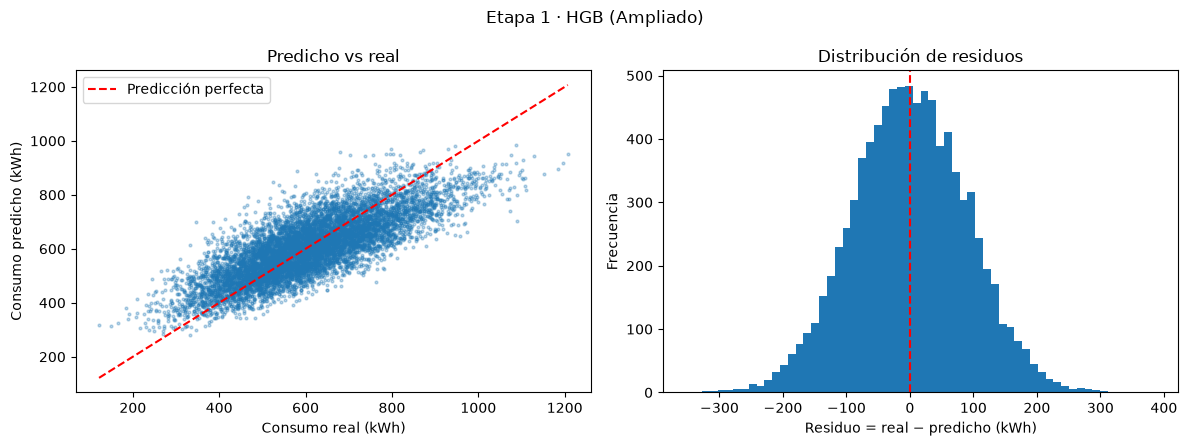

In [16]:
mejor_1 = tabla_1.index[0]
print("Mejor modelo de la etapa 1:", mejor_1)
graficar_predicciones(y_test, pred_1[mejor_1], f"Etapa 1 · {mejor_1[1]} ({mejor_1[0]})")

## 7. Etapa 2: variables elegidas mediante análisis exploratorio
Ahora las variables se eligen **a partir de los datos**. El análisis se hace **solo con el conjunto de
entrenamiento**: si se usara el test para elegir variables, su MAE ya no sería una estimación imparcial.

Se usan dos herramientas que se complementan:
1. **Correlación de Pearson** de las variables numéricas con el consumo. Solo detecta relaciones lineales.
   Además se comprueba la correlación entre las predictoras para descartar variables **redundantes**.
2. **Consumo medio por categoría** para las variables categóricas.

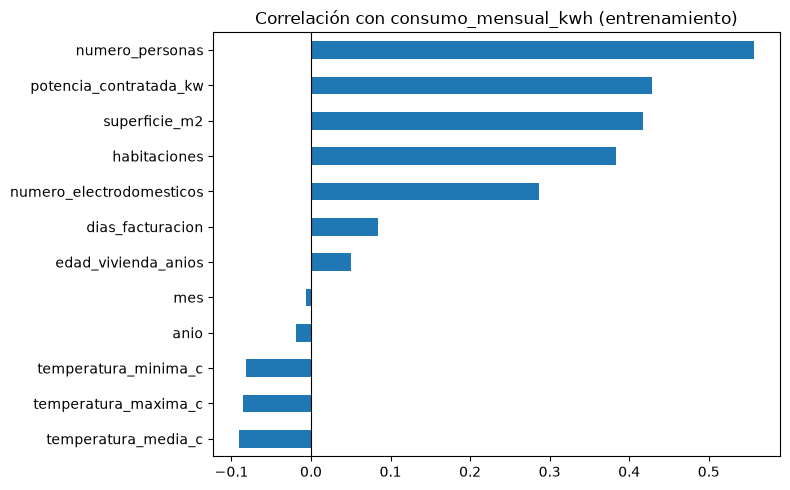

In [17]:
# 7.1 Correlación de las variables numéricas con el consumo (solo entrenamiento)
entreno = X_train_todo.assign(**{OBJETIVO: y_train})
corr = (entreno.select_dtypes("number").corr()[OBJETIVO]
        .drop(OBJETIVO).sort_values())

corr.plot.barh(figsize=(8, 5), title="Correlación con consumo_mensual_kwh (entrenamiento)")
plt.axvline(0, color="k", lw=0.8)
plt.tight_layout(); plt.show()

In [18]:
# 7.1 (cont.) Redundancia entre las variables numéricas más correlacionadas con el consumo
# Si dos predictoras están muy correlacionadas entre sí (|r| > 0,7), aportan casi la misma información
# y basta con quedarse con la que más se relaciona con el consumo.
mas_correladas = corr[corr.abs() > 0.2].sort_values(ascending=False).index
entreno[mas_correladas].corr().round(2)

,numero_personas,potencia_contratada_kw,superficie_m2,habitaciones,numero_electrodomesticos
numero_personas,1.00,0.78,-0.00,0.00,0.01
potencia_contratada_kw,0.78,1.00,-0.01,-0.00,0.01
superficie_m2,-0.00,-0.01,1.00,0.84,0.00
habitaciones,0.00,-0.00,0.84,1.00,0.00
numero_electrodomesticos,0.01,0.01,0.00,0.00,1.00


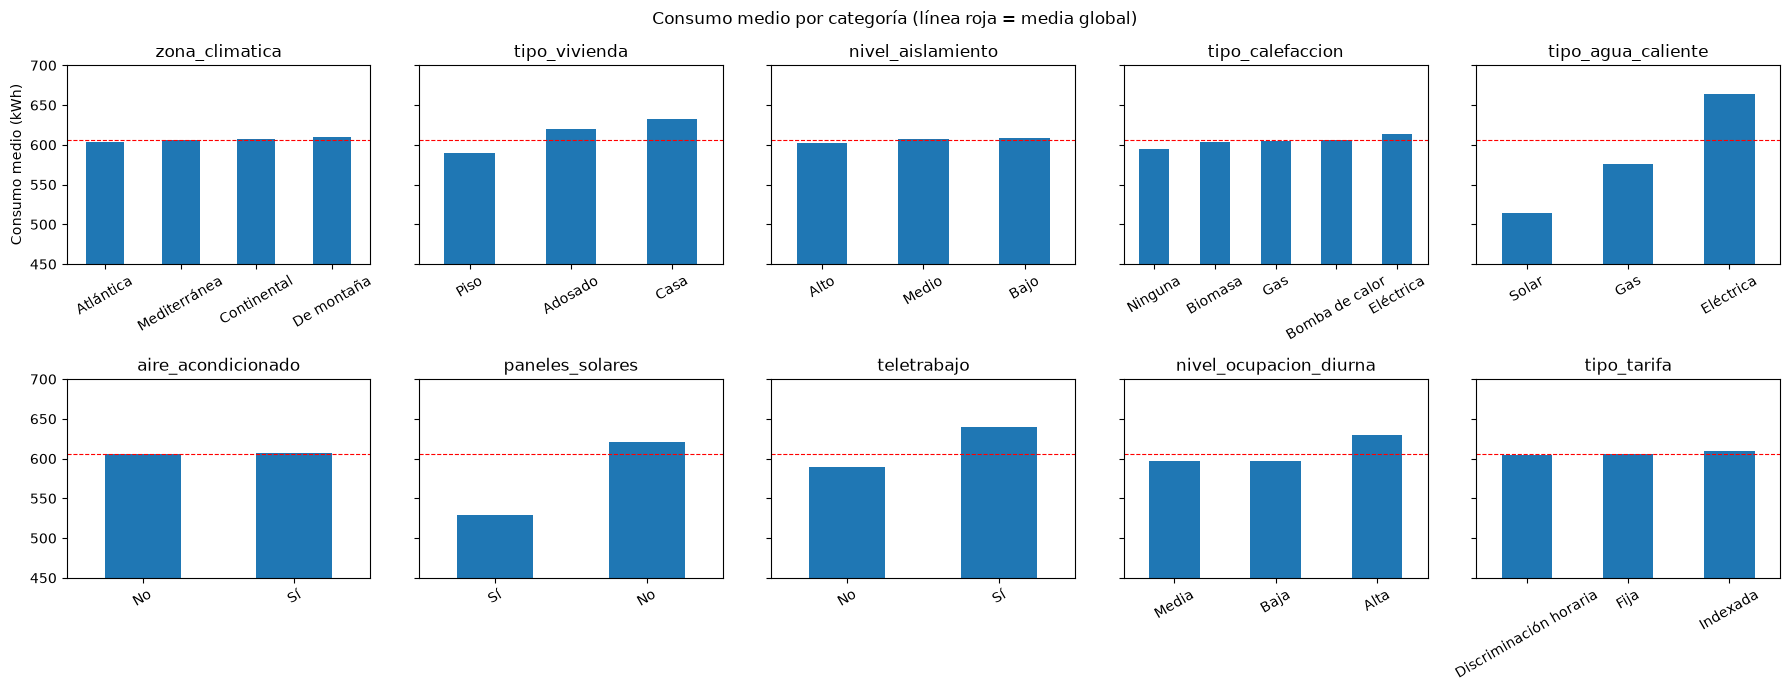

,Diferencia máx-mín (kWh)
tipo_agua_caliente,149.2
paneles_solares,91.1
teletrabajo,49.8
tipo_vivienda,42.4
nivel_ocupacion_diurna,33.4
tipo_calefaccion,19.0
nivel_aislamiento,6.8
zona_climatica,6.7
tipo_tarifa,5.0
aire_acondicionado,1.6


In [19]:
# 7.2 Consumo medio por categoría (solo entrenamiento)
categoricas = X_train_todo.select_dtypes(exclude="number").columns
fig, axes = plt.subplots(2, 5, figsize=(18, 7), sharey=True)
for ax, col in zip(axes.ravel(), categoricas):
    entreno.groupby(col)[OBJETIVO].mean().sort_values().plot.bar(ax=ax, rot=30)
    ax.axhline(y_train.mean(), color="r", ls="--", lw=0.8)
    ax.set(title=col, xlabel="")
    ax.set_ylim(450, 700)
axes[0, 0].set_ylabel("Consumo medio (kWh)")
fig.suptitle("Consumo medio por categoría (línea roja = media global)")
plt.tight_layout(); plt.show()

# Diferencia entre la categoría con más y con menos consumo: indica cuánto separa la variable
medias = {col: entreno.groupby(col)[OBJETIVO].mean() for col in categoricas}
rango_cat = {col: m.max() - m.min() for col, m in medias.items()}
pd.Series(rango_cat, name="Diferencia máx-mín (kWh)").sort_values(ascending=False).round(1).to_frame()

**Selección.** Se combinan los dos análisis:

- **Numéricas:** las que tienen una correlación con el consumo mayor que 0,2, descartando las redundantes.
  `potencia_contratada_kw` está muy correlacionada con `numero_personas` (r ≈ 0,78) y `habitaciones` con
  `superficie_m2` (r ≈ 0,84): no aportan información nueva, así que se quedan `numero_personas`,
  `superficie_m2` y `numero_electrodomesticos`.
- **Categóricas:** se ordenan por la diferencia de consumo entre su categoría máxima y mínima.

El **conjunto reducido** lo forman las 3 numéricas y las 2 categóricas que más separan el consumo
(5 variables). El **ampliado** añade las 3 categóricas siguientes (8 variables).

Observaciones para la memoria:
- `tipo_agua_caliente` y `teletrabajo` no estaban en la etapa 1 y separan mucho el consumo.
- `nivel_aislamiento` y `aire_acondicionado` (etapa 1) apenas cambian el consumo medio.

In [20]:
REDUNDANTES = ["potencia_contratada_kw", "habitaciones"]   # ver la matriz de correlación anterior
numericas_2 = [v for v in mas_correladas if v != OBJETIVO and v not in REDUNDANTES]
ranking_cat = pd.Series(rango_cat).sort_values(ascending=False).index.tolist()

cols_reducida_2 = numericas_2 + ranking_cat[:2]
cols_ampliada_2 = numericas_2 + ranking_cat[:5]
print("Numéricas elegidas:", numericas_2)
print("Conjunto reducido (etapa 2):", cols_reducida_2)
print("Conjunto ampliado (etapa 2):", cols_ampliada_2)

Xtr_2, nominales_2 = numerizar(X_train_todo[cols_ampliada_2])
Xte_2, _ = numerizar(X_test_todo[cols_ampliada_2])
print("Variables nominales:", nominales_2)

Numéricas elegidas: ['numero_personas', 'superficie_m2', 'numero_electrodomesticos']
Conjunto reducido (etapa 2): ['numero_personas', 'superficie_m2', 'numero_electrodomesticos', 'tipo_agua_caliente', 'paneles_solares']
Conjunto ampliado (etapa 2): ['numero_personas', 'superficie_m2', 'numero_electrodomesticos', 'tipo_agua_caliente', 'paneles_solares', 'teletrabajo', 'tipo_vivienda', 'nivel_ocupacion_diurna']
Variables nominales: ['tipo_agua_caliente', 'tipo_vivienda']


In [21]:
tabla_2, pred_2, modelos_2 = ejecutar_etapa(
    {"Reducido": cols_reducida_2, "Ampliado": cols_ampliada_2},
    Xtr_2, y_train, Xte_2, y_test, nominales_2)

print("=== ETAPA 2 · Resultados (ordenados por MAE de test) ===")
tabla_2

=== ETAPA 2 · Resultados (ordenados por MAE de test) ===


MAE train  MAE test  MAE test %  R2 train  R2 test
Conjunto Modelo                                                           
Ampliado HGB               48.141    49.734       8.204     0.828    0.816
         Random Forest     40.838    52.766       8.704     0.875    0.791
         Ridge             52.814    52.988       8.741     0.794    0.790
         Lineal            52.814    52.988       8.741     0.794    0.790
Reducido HGB               54.831    56.041       9.244     0.779    0.766
         Ridge             58.553    58.496       9.649     0.747    0.745
         Lineal            58.553    58.497       9.649     0.747    0.745
         Random Forest     46.892    58.686       9.680     0.836    0.744

Mejor modelo de la etapa 2: ('Ampliado', 'HGB')


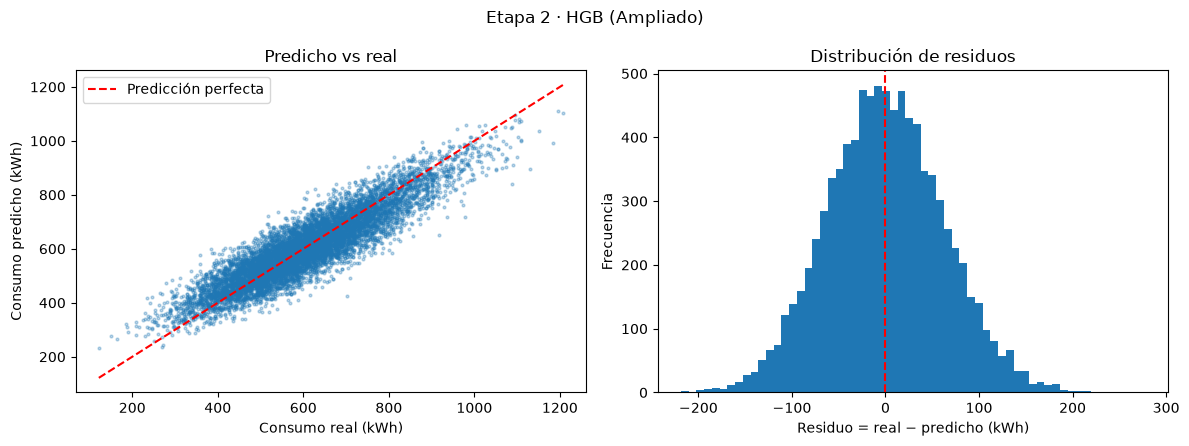

In [22]:
mejor_2 = tabla_2.index[0]
print("Mejor modelo de la etapa 2:", mejor_2)
graficar_predicciones(y_test, pred_2[mejor_2], f"Etapa 2 · {mejor_2[1]} ({mejor_2[0]})")

## 8. Comparación final de ambas etapas
Se juntan los MAE de test de todas las combinaciones (etapa × conjunto × modelo) en una tabla y un gráfico.

In [23]:
comparativa = pd.concat({"Etapa 1 (a priori)": tabla_1["MAE test"],
                         "Etapa 2 (EDA)": tabla_2["MAE test"]}, axis=1)
comparativa["Mejora (kWh)"] = comparativa["Etapa 1 (a priori)"] - comparativa["Etapa 2 (EDA)"]
comparativa = comparativa.sort_index().round(2)
print(f"MAE de test en kWh · consumo medio: {CONSUMO_MEDIO:.1f}")
comparativa

MAE de test en kWh · consumo medio: 606.2


Etapa 1 (a priori)  Etapa 2 (EDA)  Mejora (kWh)
Conjunto Modelo                                                        
Ampliado HGB                         71.88          49.73         22.14
         Lineal                      71.93          52.99         18.95
         Random Forest               74.01          52.77         21.24
         Ridge                       71.93          52.99         18.95
Reducido HGB                         78.56          56.04         22.52
         Lineal                      78.65          58.50         20.15
         Random Forest               81.23          58.69         22.54
         Ridge                       78.65          58.50         20.15

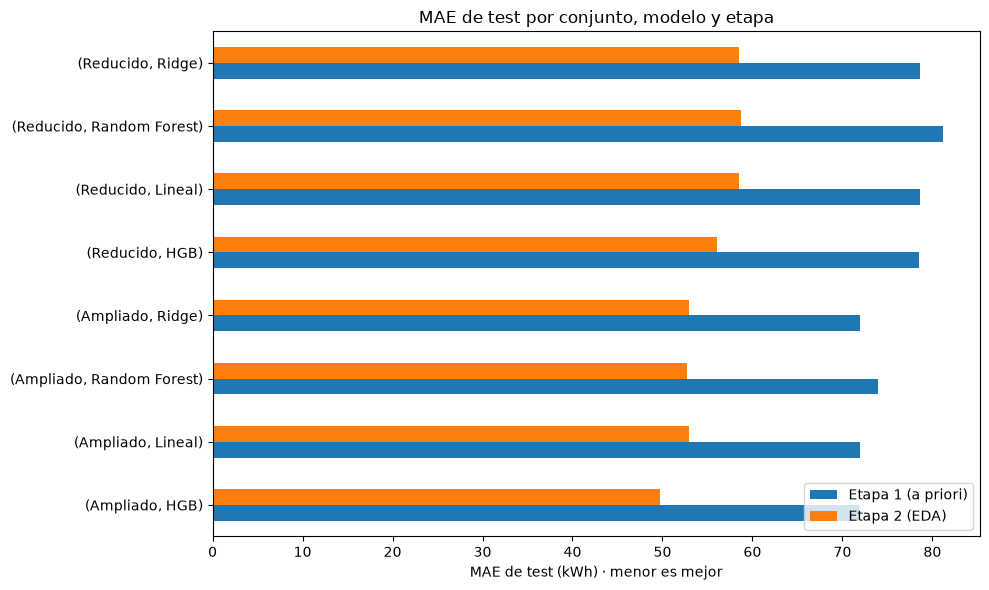

In [24]:
ax = comparativa[["Etapa 1 (a priori)", "Etapa 2 (EDA)"]].plot.barh(figsize=(10, 6))
ax.set(xlabel="MAE de test (kWh) · menor es mejor", ylabel="",
       title="MAE de test por conjunto, modelo y etapa")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

Mejor modelo global: HGB · conjunto Ampliado · Etapa 2


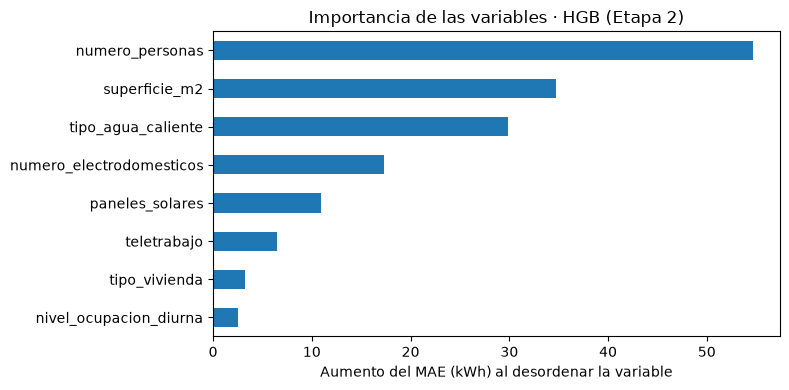

In [25]:
# Importancia de las variables en el mejor modelo global (interpretación de sus predicciones)
mejor_global = mejor_2 if tabla_2["MAE test"].iloc[0] <= tabla_1["MAE test"].iloc[0] else mejor_1
etapa = "Etapa 2" if mejor_global == mejor_2 else "Etapa 1"
modelo = (modelos_2 if etapa == "Etapa 2" else modelos_1)[mejor_global]
cols = (cols_reducida_2 if etapa == "Etapa 2" else cols_reducida_1) if mejor_global[0] == "Reducido" \
       else (cols_ampliada_2 if etapa == "Etapa 2" else cols_ampliada_1)
Xte = Xte_2 if etapa == "Etapa 2" else Xte_1

print(f"Mejor modelo global: {mejor_global[1]} · conjunto {mejor_global[0]} · {etapa}")
perm = permutation_importance(modelo, Xte[cols], y_test, scoring="neg_mean_absolute_error",
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
pd.Series(perm.importances_mean, index=cols).sort_values().plot.barh(
    figsize=(8, 4), title=f"Importancia de las variables · {mejor_global[1]} ({etapa})")
plt.xlabel("Aumento del MAE (kWh) al desordenar la variable")
plt.tight_layout(); plt.show()

### Conclusiones
*(Rellenar en la memoria a partir de las tablas anteriores.)*

- **¿Qué algoritmo ha obtenido el menor MAE?**
- **¿Qué influencia ha tenido la selección de variables?** Compara la etapa 1 con la 2 y el conjunto reducido con el ampliado.
- **¿Qué modelo elegirías para producción?** Ten en cuenta el MAE, el coste de entrenamiento e
  inferencia y la interpretabilidad.
- **Ridge frente a regresión lineal:** dan resultados prácticamente iguales. Con ≈21 000 filas y como mucho 8
  variables el modelo lineal no tiene nada que regularizar, así que `RidgeCV` elige una regularización casi nula.